# EDA — Jigsaw Toxic Comment Classification Challenge

Task: Supervised Multi-label Binary Classification (6 labels)
Labels: `toxic, severe_toxic, obscene, threat, insult, identity_hate`

In [1]:
import os
import sys
sys.path.append(os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import LABEL_COLS, SEED
from src.data_loader import load_train_data, get_train_val_split, load_test_data

In [2]:
# 1. Muat Split Train & Validation
df_train, df_val = get_train_val_split()
print(f"Train size: {len(df_train)}")
print(f"Val size:   {len(df_val)}")
df_train.head()

Train size: 143613
Val size:   15958


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


               Count  Percentage (%)
toxic          13765        9.584787
severe_toxic    1435        0.999213
obscene         7604        5.294785
threat           430        0.299416
insult          7089        4.936183
identity_hate   1264        0.880143


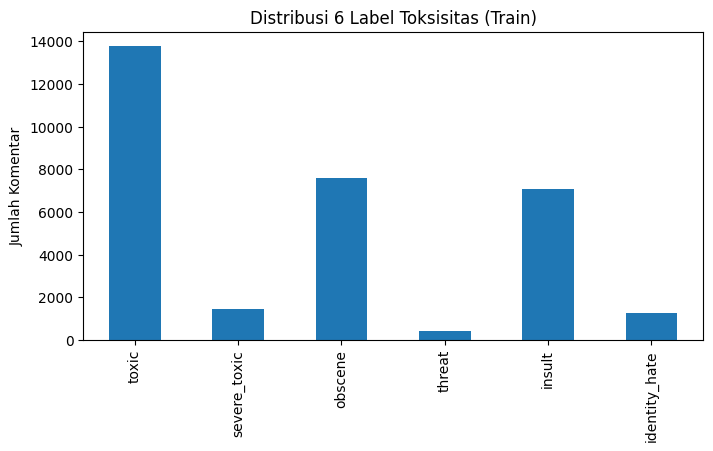

In [3]:
# 2. Frekuensi & Proporsi 6 Label (ML-T3-01)
label_counts = df_train[LABEL_COLS].sum()
label_prop = (label_counts / len(df_train)) * 100

summary_df = pd.DataFrame({'Count': label_counts, 'Percentage (%)': label_prop})
print(summary_df)

summary_df['Count'].plot(kind='bar', figsize=(8, 4), title='Distribusi 6 Label Toksisitas (Train)')
plt.ylabel('Jumlah Komentar')
plt.show()

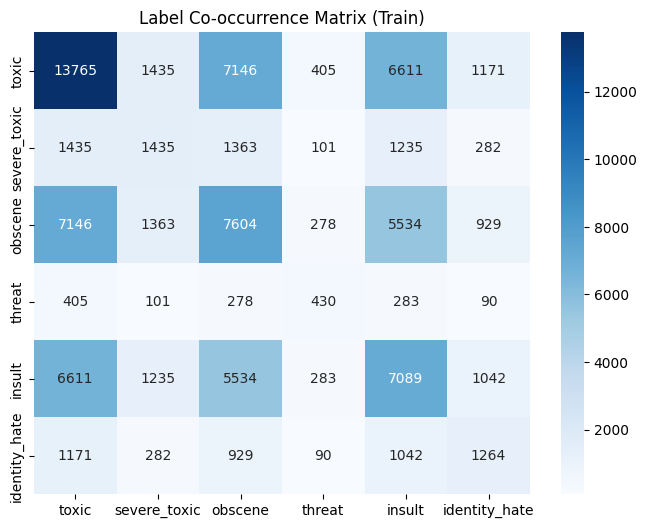

In [4]:
# 3. Co-occurrence Matrix (ML-T3-03)
cooc = df_train[LABEL_COLS].T.dot(df_train[LABEL_COLS])
plt.figure(figsize=(8, 6))
sns.heatmap(cooc, annot=True, fmt='d', cmap='Blues')
plt.title('Label Co-occurrence Matrix (Train)')
plt.show()

In [5]:
# 4. Cek Data Test Scored vs Unscored (ML-T2-03)
df_test_valid = load_test_data(drop_unscored=True)
print(f"Valid scored test comments: {len(df_test_valid)} baris")
print(df_test_valid[LABEL_COLS].sum())

Valid scored test comments: 63978 baris
toxic            6090
severe_toxic      367
obscene          3691
threat            211
insult           3427
identity_hate     712
dtype: int64
